# Week 3 – Grid search, models and ensembles

Follow-up of `04_baseline.ipynb`, applying **part II of lab 6** to the project:
1. **Grid search** on the baseline (logistic regression) to find its best configuration.
2. Other models: **decision tree**, **random forest**, **gradient boosting**, **MLP** (out-of-course model) and **SVM**.
3. **Ensembles**: Bagging, Voting (average of the probabilities) and Stacking.
4. **Uncertainty**: bootstrap confidence intervals and paired comparison with the baseline.
5. Figures and comparison table (performance, time, interpretability).
6. Impact of the hours-played leak (AI_AUDIT, Flaw 2).
7. Final evaluation on the test set (disabled until the final model is chosen).

| Section | Owner |
|---|---|
| 1. Grid search on the logistic regression | Lucas GREZES |
| 2. Decision tree and random forest | Arthur DISERBEAU |
| 3. Gradient boosting | Yohan ALLOUCHE |
| 4. MLP | Jason ZOH |
| 5. SVM, bagging and ensembles | Lucas GREZES |
| 6. Uncertainty | Arthur DISERBEAU |
| 7–9. Figures, hours leak, test | Lucas GREZES |

**Lab 6 traps, adapted to our project**

| Lab 6 trap | What we do here |
|---|---|
| random `cv=2` | `PredefinedSplit`: tuning is done on **our time-based validation set**, never on random folds |
| `scoring="accuracy"` | `scoring="average_precision"` (PR-AUC): imbalanced classes (~15% of successes) |
| scaling outside the pipeline | imputation, scaling and encoding **inside** the pipeline, fitted on the train set |
| `refit=True` | `refit=False`: with `PredefinedSplit`, `refit=True` would retrain on train + validation and we could no longer evaluate on the validation set |
| evaluating on the test set to choose | the test set is used **only once**, at the end |
| `random_state` forgotten | `random_state=SEED` everywhere |

In [1]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, BaggingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit, KFold
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)
from config import *

FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

target = pd.read_parquet(PROC_DIR / "target.parquet")
static = pd.read_parquet(PROC_DIR / "features_static.parquet")
print("Games:", len(target), "| Static features:", static.shape)

Games: 10000 | Static features: (10000, 217)


## 0. Data, pipeline and helper functions (same as notebook 04)

We reuse exactly `make_dataset` and the preprocessor of notebook 04, so that the baseline is comparable.
The games are **sorted by release date** (useful for Stacking, section 5).

In [2]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]
T_LIST = T_VALUES  # [0, 7, 30, 90]

def make_dataset(T):
    df = target[["app_id", "release_date", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df.sort_values(["release_date", "app_id"]).reset_index(drop=True)

def make_preprocess(df):
    num = [c for c in NUM_COLS if c in df.columns]
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        remainder="passthrough")

DATA = {}
for T in T_LIST:
    df = make_dataset(T)
    tr, va = df[df["split"] == "train"], df[df["split"] == "val"]
    X_cols = [c for c in df.columns if c not in ["app_id", "release_date", "split", "success"]]
    DATA[T] = dict(df=df, Xtr=tr[X_cols], ytr=tr["success"], Xva=va[X_cols], yva=va["success"])
    assert tr["release_date"].max() < va["release_date"].min()   # no shared release day

print({T: DATA[T]["Xtr"].shape for T in T_LIST})
print("Share of successes in validation (PR-AUC of a random model):", round(DATA[0]["yva"].mean(), 3))

{0: (7007, 216), 7: (7007, 219), 30: (7007, 219), 90: (7007, 219)}
Share of successes in validation (PR-AUC of a random model): 0.157


In [3]:
def predefined_split(d):
    # train = -1 (never in validation), val = 0 (the only validation fold)
    X = pd.concat([d["Xtr"], d["Xva"]])
    y = pd.concat([d["ytr"], d["yva"]])
    fold = np.r_[np.full(len(d["Xtr"]), -1), np.zeros(len(d["Xva"]))]
    return X, y, PredefinedSplit(fold)

def evaluate(model, d, name, T, fit_time=np.nan):
    t0 = time.perf_counter()
    p = model.predict_proba(d["Xva"])[:, 1]
    pred_time = time.perf_counter() - t0
    yhat = (p >= 0.5).astype(int)
    return dict(model=name, T=T, **{"PR-AUC": average_precision_score(d["yva"], p),
                "ROC-AUC": roc_auc_score(d["yva"], p),
                "F1": f1_score(d["yva"], yhat, zero_division=0),
                "precision": precision_score(d["yva"], yhat, zero_division=0),
                "recall": recall_score(d["yva"], yhat, zero_division=0),
                "fit_s": fit_time, "predict_s": pred_time}), p

def fit_timed(model, d):
    t0 = time.perf_counter()
    model.fit(d["Xtr"], d["ytr"])
    return model, time.perf_counter() - t0

ROWS, PROBA, MODELS, BEST_PARAMS = [], {}, {}, {}

def record(model, d, name, T, fit_time):
    row, p = evaluate(model, d, name, T, fit_time)
    ROWS.append(row); PROBA[(name, T)] = p; MODELS[(name, T)] = model
    return row

def tune(name, clf, grid, n_iter=8):
    # n_iter=None: full grid search; otherwise random search over n_iter configurations
    for T in T_LIST:
        d = DATA[T]
        pipe = make_pipeline(make_preprocess(d["df"]), clf)
        X, y, ps = predefined_split(d)
        if n_iter is None:
            search = GridSearchCV(pipe, grid, scoring="average_precision", cv=ps, refit=False, n_jobs=-1)
        else:
            search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring="average_precision", cv=ps,
                                        refit=False, random_state=SEED, n_jobs=-1)
        search.fit(X, y)
        BEST_PARAMS[(name, T)] = search.best_params_
        best, ft = fit_timed(clone(pipe).set_params(**search.best_params_), d)  # refit on the train set only
        row = record(best, d, name, T, ft)
        print(f"{name:<18} T={T:>2} PR-AUC val = {row['PR-AUC']:.3f}  {search.best_params_}")

## 1. Grid search on the baseline logistic regression (Lucas GREZES)

The baseline of notebook 04: `LogisticRegression(max_iter=1000, class_weight="balanced")`, with `C = 1` and the default
L2 penalty. We search:
- `C`: the strength of the regularisation (small `C` = smaller coefficients = simpler model, less variance);
- `l1_ratio`: 0 = L2 penalty (Ridge), 1 = L1 penalty (Lasso, sets coefficients to 0: feature selection);
- `class_weight`: `None` or `"balanced"`.

With scikit-learn 1.9, the `penalty` parameter is deprecated: we use `l1_ratio` with the `saga` solver
(the only solver that accepts both L1 and L2).

In [4]:
LR_GRID = {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3],
           "logisticregression__l1_ratio": [0, 1],
           "logisticregression__class_weight": [None, "balanced"]}
BEST_LR = {}

for T in T_LIST:
    d = DATA[T]
    base = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    base, ft = fit_timed(base, d)
    record(base, d, "LogReg (baseline 04)", T, ft)

    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED))
    X, y, ps = predefined_split(d)
    gs = GridSearchCV(pipe, LR_GRID, scoring="average_precision", cv=ps, refit=False, n_jobs=-1)
    gs.fit(X, y)
    BEST_LR[T] = gs.best_params_
    best, ft = fit_timed(clone(pipe).set_params(**gs.best_params_), d)   # refit on the train set only
    record(best, d, "LogReg (grid search)", T, ft)
    print(f"T={T:>2} best parameters: {gs.best_params_} | PR-AUC val = {gs.best_score_:.3f}")

T= 0 best parameters: {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.456


T= 7 best parameters: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.821


T=30 best parameters: {'logisticregression__C': 0.1, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.862


T=90 best parameters: {'logisticregression__C': 0.3, 'logisticregression__class_weight': None, 'logisticregression__l1_ratio': 1} | PR-AUC val = 0.885


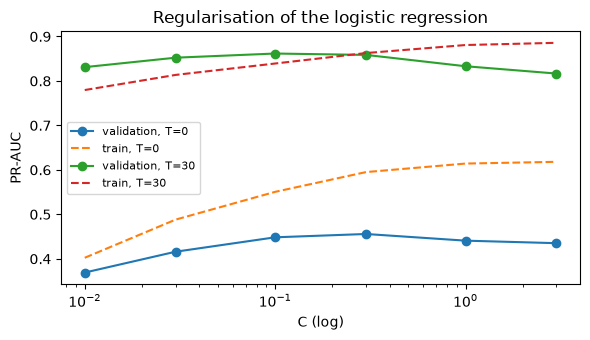

In [5]:
# Effect of C on the validation PR-AUC (bias / variance), at T = 0 and T = 30
fig, ax = plt.subplots(figsize=(6, 3.5))
for T in [0, 30]:
    d = DATA[T]; X, y, ps = predefined_split(d)
    pipe = make_pipeline(make_preprocess(d["df"]),
                         LogisticRegression(solver="saga", max_iter=3000, random_state=SEED,
                                            l1_ratio=BEST_LR[T]["logisticregression__l1_ratio"],
                                            class_weight=BEST_LR[T]["logisticregression__class_weight"]))
    gs = GridSearchCV(pipe, {"logisticregression__C": LR_GRID["logisticregression__C"]},
                      scoring="average_precision", cv=ps, refit=False, return_train_score=True, n_jobs=-1).fit(X, y)
    r = pd.DataFrame(gs.cv_results_)
    ax.plot(r["param_logisticregression__C"], r["mean_test_score"], marker="o", label=f"validation, T={T}")
    ax.plot(r["param_logisticregression__C"], r["mean_train_score"], ls="--", label=f"train, T={T}")
ax.set(xscale="log", xlabel="C (log)", ylabel="PR-AUC", title="Regularisation of the logistic regression")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "logreg_C.png", dpi=150); plt.show()

**Reading:** on the left (small `C`), the model is too constrained: train and validation are both low (**bias**).
On the right (large `C`), the train score keeps rising while the validation score stalls or drops: the model
starts to learn the noise of the train set (**variance**). The best `C` is where the validation score is highest.

## 2. Decision tree and random forest (Arthur DISERBEAU)

### 2.1 Decision tree (lab 6, exercise 1)

A decision tree splits the games with a sequence of questions ("is `n_reviews` at T = 7 above x?", then "is `pos_ratio` above y?"…) and gives each leaf the share of successes of its training games as probability. It is the building block of the random forest: comparing the two shows what bagging brings.

Full grid search (80 configurations, the tree is fast to train):
- `criterion`: impurity measure used to choose the splits (`gini` or `entropy`);
- `max_depth`: maximum number of questions in a row (`None` = no limit);
- `min_samples_leaf`: minimum number of games in a leaf (prevents leaves built on 1 or 2 games);
- `class_weight`: `None` or `"balanced"`.

In [6]:
TREE_GRID = {"decisiontreeclassifier__criterion": ["gini", "entropy"],
             "decisiontreeclassifier__max_depth": [3, 5, 8, 12, None],
             "decisiontreeclassifier__min_samples_leaf": [1, 5, 20, 50],
             "decisiontreeclassifier__class_weight": [None, "balanced"]}
tune("Decision tree", DecisionTreeClassifier(random_state=SEED), TREE_GRID, n_iter=None)

Decision tree      T= 0 PR-AUC val = 0.402  {'decisiontreeclassifier__class_weight': None, 'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 20}


Decision tree      T= 7 PR-AUC val = 0.837  {'decisiontreeclassifier__class_weight': None, 'decisiontreeclassifier__criterion': 'entropy', 'decisiontreeclassifier__max_depth': 8, 'decisiontreeclassifier__min_samples_leaf': 50}


Decision tree      T=30 PR-AUC val = 0.901  {'decisiontreeclassifier__class_weight': None, 'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 12, 'decisiontreeclassifier__min_samples_leaf': 50}


Decision tree      T=90 PR-AUC val = 0.925  {'decisiontreeclassifier__class_weight': None, 'decisiontreeclassifier__criterion': 'gini', 'decisiontreeclassifier__max_depth': 5, 'decisiontreeclassifier__min_samples_leaf': 50}


**Bias / variance trade-off (lab 6 questions).** We fix `min_samples_leaf = 1` (the most flexible value) and let `max_depth` grow, at T = 30. The train and validation PR-AUC are compared for each depth.

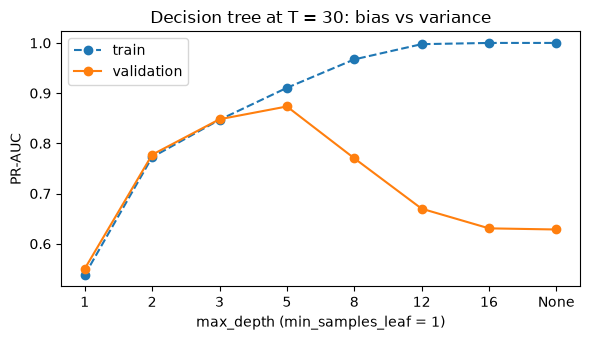

In [7]:
d = DATA[30]; X, y, ps = predefined_split(d)
DEPTHS = [1, 2, 3, 5, 8, 12, 16, None]
pipe = make_pipeline(make_preprocess(d["df"]), DecisionTreeClassifier(min_samples_leaf=1, random_state=SEED))
gs = GridSearchCV(pipe, {"decisiontreeclassifier__max_depth": DEPTHS}, scoring="average_precision",
                  cv=ps, refit=False, return_train_score=True, n_jobs=-1).fit(X, y)
r = pd.DataFrame(gs.cv_results_)

fig, ax = plt.subplots(figsize=(6, 3.5))
labels = [str(m) for m in DEPTHS]
ax.plot(labels, r["mean_train_score"], marker="o", ls="--", label="train")
ax.plot(labels, r["mean_test_score"], marker="o", label="validation")
ax.set(xlabel="max_depth (min_samples_leaf = 1)", ylabel="PR-AUC", title="Decision tree at T = 30: bias vs variance")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "tree_depth.png", dpi=150); plt.show()

**What to look for:** with a small depth, train and validation are both low (**bias**: the tree is too simple). When `max_depth = None` and `min_samples_leaf = 1`, the tree can isolate every training game: the train PR-AUC gets close to 1 while the validation PR-AUC drops (**variance**: the tree learns the noise). The best tree is in between, and a single tree stays unstable: this is what the random forest corrects by averaging many trees.

**Reading (Arthur):** up to depth 3, train and validation are equal and low (≈ 0.85 at depth 3): the tree is too simple (**bias**). With `min_samples_leaf = 1`, the validation PR-AUC peaks at depth 5 (≈ 0.87, train ≈ 0.91). Deeper, the train score reaches 1 from depth 12 while the validation score falls to ≈ 0.63 at `max_depth = None`: a gap of about 0.37, the tree learns the training games by heart (**variance**). The grid search finds a better tree (0.901 at T = 30) with depth 12 but at least 50 games per leaf: `min_samples_leaf` is a second way to limit the variance, besides the depth.

**The rules of a small tree.** A tree limited to depth 3 (other parameters: the best ones at T = 30) can be read as a few rules. The numerical thresholds are on **scaled** values (`StandardScaler`: 0 = mean of the train set), and `n_reviews` is in log.

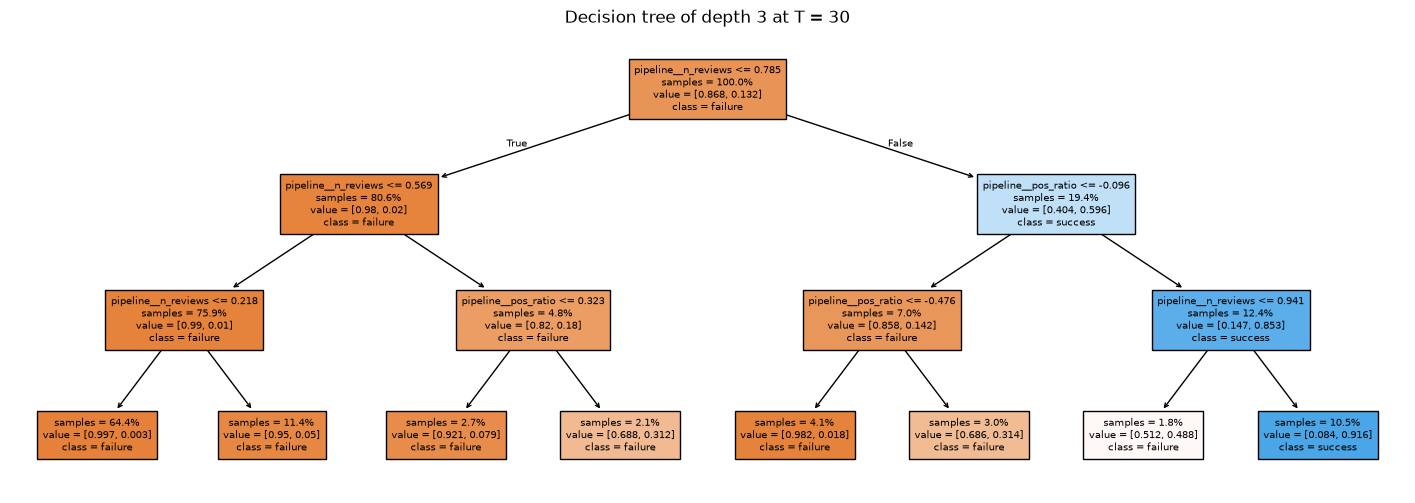

In [8]:
small = clone(MODELS[("Decision tree", 30)]).set_params(decisiontreeclassifier__max_depth=3)
small.fit(DATA[30]["Xtr"], DATA[30]["ytr"])

plt.figure(figsize=(18, 6))
plot_tree(small[-1], feature_names=small[0].get_feature_names_out(), class_names=["failure", "success"],
          filled=True, proportion=True, impurity=False, fontsize=7)
plt.title("Decision tree of depth 3 at T = 30")
plt.savefig(FIG_DIR / "tree_T30.png", dpi=150, bbox_inches="tight"); plt.show()

### 2.2 Random forest

Many deep trees, each trained on a bootstrap sample of the games (= *bagging* of trees), with a random subset of features at each split. Averaging them reduces the variance of a single tree.

Random search (`RandomizedSearchCV`, 8 configurations per model and per T, limited budget) rather than a full grid: for the same budget, it explores more different values of each parameter (Bergstra and Bengio, 2012).

In [9]:
RF_GRID = {"randomforestclassifier__n_estimators": [200, 400],
           "randomforestclassifier__max_depth": [None, 8, 16, 32],
           "randomforestclassifier__min_samples_leaf": [1, 3, 10, 30],
           "randomforestclassifier__max_features": ["sqrt", 0.2, 0.4],
           "randomforestclassifier__class_weight": [None, "balanced_subsample"]}
# n_jobs=1: the search already runs its configurations in parallel (AI_AUDIT, Flaw 7)
tune("Random forest", RandomForestClassifier(random_state=SEED, n_jobs=1), RF_GRID)

Random forest      T= 0 PR-AUC val = 0.489  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__max_depth': 32, 'randomforestclassifier__class_weight': None}


Random forest      T= 7 PR-AUC val = 0.866  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': None, 'randomforestclassifier__class_weight': None}


Random forest      T=30 PR-AUC val = 0.910  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


Random forest      T=90 PR-AUC val = 0.944  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_features': 0.4, 'randomforestclassifier__max_depth': 8, 'randomforestclassifier__class_weight': None}


## 3. Gradient boosting (Yohan ALLOUCHE)

`HistGradientBoostingClassifier`: small trees added one by one, each one correcting the errors of the previous ones (it reduces the bias, whereas the random forest reduces the variance). The features are grouped into bins (histograms), which makes it fast.

- `learning_rate`: weight of each new tree (small = slower but more careful learning);
- `max_leaf_nodes`, `min_samples_leaf`: size of each tree;
- `l2_regularization`: penalty on the leaf values. The first run chose 1, the largest value tested, so the grid now goes up to 10;
- `max_iter`: number of trees.

In [10]:
GB_GRID = {"histgradientboostingclassifier__learning_rate": [0.03, 0.05, 0.1],
           "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
           "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
           "histgradientboostingclassifier__l2_regularization": [0, 0.1, 1, 10],
           "histgradientboostingclassifier__max_iter": [200, 400],
           "histgradientboostingclassifier__class_weight": [None, "balanced"]}
tune("Gradient boosting", HistGradientBoostingClassifier(random_state=SEED), GB_GRID)

Gradient boosting  T= 0 PR-AUC val = 0.483  {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 31, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 0.1, 'histgradientboostingclassifier__class_weight': 'balanced'}


Gradient boosting  T= 7 PR-AUC val = 0.875  {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 31, 'histgradientboostingclassifier__max_iter': 200, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 0.1, 'histgradientboostingclassifier__class_weight': 'balanced'}


Gradient boosting  T=30 PR-AUC val = 0.917  {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 31, 'histgradientboostingclassifier__max_iter': 400, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 10, 'histgradientboostingclassifier__class_weight': 'balanced'}


Gradient boosting  T=90 PR-AUC val = 0.946  {'histgradientboostingclassifier__min_samples_leaf': 100, 'histgradientboostingclassifier__max_leaf_nodes': 31, 'histgradientboostingclassifier__max_iter': 400, 'histgradientboostingclassifier__learning_rate': 0.03, 'histgradientboostingclassifier__l2_regularization': 10, 'histgradientboostingclassifier__class_weight': 'balanced'}


## 4. MLP, out-of-course model (Jason ZOH)

A *multilayer perceptron*: a neural network with 1 or 2 hidden layers, trained with early stopping (`early_stopping`) to limit overfitting.
- `hidden_layer_sizes`: number of neurons per hidden layer;
- `alpha`: L2 penalty on the weights. The first run chose 1, the largest value tested, so the grid now goes up to 10;
- `learning_rate_init`: step size of the optimiser.

In [11]:
MLP_GRID = {"mlpclassifier__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64)],
            "mlpclassifier__alpha": [1e-3, 1e-2, 1e-1, 1, 3, 10],
            "mlpclassifier__learning_rate_init": [1e-3, 3e-3]}
tune("MLP", MLPClassifier(early_stopping=True, max_iter=300, random_state=SEED), MLP_GRID)

MLP                T= 0 PR-AUC val = 0.448  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (64, 32), 'mlpclassifier__alpha': 1}


MLP                T= 7 PR-AUC val = 0.853  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 3}


MLP                T=30 PR-AUC val = 0.895  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (128, 64), 'mlpclassifier__alpha': 3}


MLP                T=90 PR-AUC val = 0.922  {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (64, 32), 'mlpclassifier__alpha': 1}


**Note on the MLP.** On tabular data (many 0/1 features, few rows), neural networks usually do worse than
tree-based models: this is the result of Grinsztajn, Oyallon and Varoquaux (2022), *Why do tree-based models still
outperform deep learning on typical tabular data?*, NeurIPS 2022 (Datasets and Benchmarks), and of Shwartz-Ziv and
Armon (2022), *Tabular data: Deep learning is not all you need*, Information Fusion 81. We therefore use it as an
out-of-course model **to compare**, not as the favourite. *(References to check on Google Scholar before citing
them in the report.)*

## 5. SVM, bagging and ensembles (Lucas GREZES)

### 5.1 SVM (lab 6, exercise 2)

The SVM looks for the boundary that separates successes from failures with the largest margin. With the RBF kernel, this boundary can be curved. Scaling is mandatory (distances between games), and it is already in the pipeline.

Grid of lab 6 for the RBF kernel: `C` ∈ {0.1, 1, 10}, `gamma` ∈ {scale, auto}, with `class_weight="balanced"`. The **linear kernel is not tested**: it is a linear model like the logistic regression already tuned in section 1, and libsvm converges very slowly with it on 7,000 games.

The search scores the SVM on `decision_function` (signed distance to the boundary, enough to rank the games). Only the final model uses `probability=True` (Platt scaling: 5 internal folds, slow), because the comparison table and the ensembles need probabilities.

In [12]:
SVM_GRID = {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", "auto"]}

for T in T_LIST:
    d = DATA[T]; X, y, ps = predefined_split(d)
    pipe = make_pipeline(make_preprocess(d["df"]), SVC(kernel="rbf", class_weight="balanced", random_state=SEED))
    gs = GridSearchCV(pipe, SVM_GRID, scoring="average_precision", cv=ps, refit=False, n_jobs=-1).fit(X, y)
    BEST_PARAMS[("SVM", T)] = gs.best_params_
    svm, ft = fit_timed(clone(pipe).set_params(**gs.best_params_, svc__probability=True), d)
    row = record(svm, d, "SVM", T, ft)
    print(f"SVM                T={T:>2} PR-AUC val = {row['PR-AUC']:.3f}  {gs.best_params_}")

C:\Users\famil\Documents\ESILV\A4\S1\Machine Learning\SteamGameIA\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                T= 0 PR-AUC val = 0.428  {'svc__C': 1, 'svc__gamma': 'auto'}


C:\Users\famil\Documents\ESILV\A4\S1\Machine Learning\SteamGameIA\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                T= 7 PR-AUC val = 0.810  {'svc__C': 1, 'svc__gamma': 'scale'}


C:\Users\famil\Documents\ESILV\A4\S1\Machine Learning\SteamGameIA\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                T=30 PR-AUC val = 0.846  {'svc__C': 1, 'svc__gamma': 'scale'}


C:\Users\famil\Documents\ESILV\A4\S1\Machine Learning\SteamGameIA\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM                T=90 PR-AUC val = 0.873  {'svc__C': 10, 'svc__gamma': 'scale'}


### 5.2 Bagging of the SVM and of the tree, then hybrid Voting (lab 6, exercise 3)

- **Bagging**: several copies of the tuned model, each trained on a random sample of the games, then averaged. We tune `n_estimators` and `max_samples` (share of the games given to each copy), as in the lab.
- For the bagged SVM, the copies are SVMs **without** `probability=True` (it would multiply the run time by 5): the probability of the bagged SVM is then the share of the copies that vote "success".
- **Hybrid Voting**: soft voting (average of the probabilities) of the bagged SVM and the bagged tree.

The preprocessing stays **before** the bagging step: `BaggingClassifier` turns X into a numpy array and loses the column names that the `ColumnTransformer` needs (AI_AUDIT, Flaw 7).

In [13]:
BAG_GRID = {"baggingclassifier__n_estimators": [10, 25], "baggingclassifier__max_samples": [0.3, 0.5]}

for T in T_LIST:
    d = DATA[T]; X, y, ps = predefined_split(d)
    bases = {"Bagging (SVM)": clone(MODELS[("SVM", T)][-1]).set_params(probability=False),
             "Bagging (tree)": clone(MODELS[("Decision tree", T)][-1])}
    bags = {}
    for name, base in bases.items():
        bag = make_pipeline(make_preprocess(d["df"]), BaggingClassifier(base, random_state=SEED, n_jobs=-1))
        gs = GridSearchCV(bag, BAG_GRID, scoring="average_precision", cv=ps, refit=False).fit(X, y)
        bags[name], ft = fit_timed(bag.set_params(**gs.best_params_), d)
        row = record(bags[name], d, name, T, ft)
        print(f"{name:<18} T={T:>2} PR-AUC val = {row['PR-AUC']:.3f}  {gs.best_params_}")

    hybrid = VotingClassifier([("svm", clone(bags["Bagging (SVM)"])), ("tree", clone(bags["Bagging (tree)"]))],
                              voting="soft")
    hybrid, ft = fit_timed(hybrid, d)
    record(hybrid, d, "Voting (bagged SVM + tree)", T, ft)

Bagging (SVM)      T= 0 PR-AUC val = 0.351  {'baggingclassifier__max_samples': 0.5, 'baggingclassifier__n_estimators': 25}


Bagging (tree)     T= 0 PR-AUC val = 0.449  {'baggingclassifier__max_samples': 0.3, 'baggingclassifier__n_estimators': 25}


Bagging (SVM)      T= 7 PR-AUC val = 0.700  {'baggingclassifier__max_samples': 0.5, 'baggingclassifier__n_estimators': 10}


Bagging (tree)     T= 7 PR-AUC val = 0.862  {'baggingclassifier__max_samples': 0.3, 'baggingclassifier__n_estimators': 25}


Bagging (SVM)      T=30 PR-AUC val = 0.769  {'baggingclassifier__max_samples': 0.5, 'baggingclassifier__n_estimators': 10}


Bagging (tree)     T=30 PR-AUC val = 0.916  {'baggingclassifier__max_samples': 0.3, 'baggingclassifier__n_estimators': 25}


Bagging (SVM)      T=90 PR-AUC val = 0.855  {'baggingclassifier__max_samples': 0.5, 'baggingclassifier__n_estimators': 25}


Bagging (tree)     T=90 PR-AUC val = 0.944  {'baggingclassifier__max_samples': 0.3, 'baggingclassifier__n_estimators': 25}


**Reading (Lucas):** bagging clearly helps the tree: 0.901 → 0.916 at T = 30 (0.837 → 0.862 at T = 7), the level of the random forest and of the gradient boosting, because a single deep tree has a high variance. It hurts the SVM: 0.846 → 0.769 at T = 30. The probability of the bagged SVM is the vote of 10 SVMs, so it only takes 11 values and many games are tied, which breaks the ranking measured by the PR-AUC (AI_AUDIT, Flaw 9); an SVM also has less variance to remove than a deep tree. The hybrid Voting (0.904) is better than the bagged SVM but worse than the bagged tree alone (0.916): averaging with a weaker model dilutes the better one.

### 5.3 Ensembles of the best models: Voting, Bagging, Stacking

- **Soft Voting**: average of the probabilities of the tuned logistic regression, the random forest and the
  gradient boosting. Useful if the models make mistakes on different games.
- **Bagging of the logistic regression**: 25 to 50 regressions trained on bootstrap samples. The logistic regression
  has little variance, so a small gain is expected (unlike trees, hence the random forest).
  `n_estimators` and `max_samples` are tuned as in lab 6.
- **Stacking**: a meta-model (logistic regression) learns how to combine the probabilities of the three models.
  It is trained on *out-of-sample* predictions of the train set (`KFold(5)` **without shuffling**, on games sorted
  by date: each fold is a continuous period, which limits the mixing of past and future).

In [14]:
def tuned(name, T):
    return MODELS[(name, T)]

for T in T_LIST:
    d = DATA[T]
    members = [("lr", clone(tuned("LogReg (grid search)", T))),
               ("rf", clone(tuned("Random forest", T))),
               ("gb", clone(tuned("Gradient boosting", T)))]

    vote, ft = fit_timed(VotingClassifier(members, voting="soft", n_jobs=-1), d)
    record(vote, d, "Voting (LR+RF+GB)", T, ft)

    X, y, ps = predefined_split(d)
    lr_best = tuned("LogReg (grid search)", T)[-1]
    bag = make_pipeline(make_preprocess(d["df"]),
                        BaggingClassifier(clone(lr_best), random_state=SEED, n_jobs=-1))
    gs = GridSearchCV(bag, {"baggingclassifier__n_estimators": [25, 50],
                            "baggingclassifier__max_samples": [0.5, 1.0]},
                      scoring="average_precision", cv=ps, refit=False).fit(X, y)
    bag, ft = fit_timed(bag.set_params(**gs.best_params_), d)
    record(bag, d, "Bagging (LogReg)", T, ft)

    stack = StackingClassifier(members, final_estimator=LogisticRegression(max_iter=1000),
                               cv=KFold(5, shuffle=False), stack_method="predict_proba", n_jobs=-1)
    stack, ft = fit_timed(stack, d)
    record(stack, d, "Stacking", T, ft)
    print(f"T={T:>2} ensembles trained (bagging: {gs.best_params_})")

results = pd.DataFrame(ROWS)
results.pivot(index="model", columns="T", values="PR-AUC").round(3).sort_values(30, ascending=False)

T= 0 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T= 7 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T=30 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 50})


T=90 ensembles trained (bagging: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 25})


T,0,7,30,90
model,,,,
Gradient boosting,0.483,0.875,0.917,0.946
Bagging (tree),0.449,0.862,0.916,0.944
Stacking,0.496,0.872,0.915,0.946
Voting (LR+RF+GB),0.495,0.872,0.914,0.945
Random forest,0.489,0.866,0.910,0.944
Voting (bagged SVM + tree),0.461,0.854,0.904,0.932
Decision tree,0.402,0.837,0.901,0.925
MLP,0.448,0.853,0.895,0.922
Bagging (LogReg),0.451,0.822,0.862,0.884


## 6. Uncertainty: confidence intervals and comparison with the baseline (Arthur DISERBEAU)

The validation set only has 1,499 games, with about 235 successes: a PR-AUC difference of 0.01 may be
noise. We resample the validation games 1,000 times (bootstrap):
- **95% CI** of the PR-AUC of each model;
- **paired comparison** with the baseline of notebook 04: both models are evaluated **on the same resampled
  games**, which removes the common variability. If the interval of the difference contains 0, the gain is not
  significant.

Assumption: the games are independent. This is approximate (same publisher, same month), so the intervals are
rather optimistic. Another limit: many models are compared on the same validation set, so the score of the
best one is slightly optimistic; the test set (section 9) gives the unbiased estimate.

In [15]:
N_BOOT = 1000
y_val = DATA[0]["yva"].to_numpy()          # the same validation games for every T
rng = np.random.default_rng(SEED)
BOOT_IDX = [i for i in (rng.integers(0, len(y_val), len(y_val)) for _ in range(N_BOOT)) if y_val[i].any()]

def boot_scores(p):
    return np.array([average_precision_score(y_val[i], p[i]) for i in BOOT_IDX])

for T in T_LIST:
    assert (DATA[T]["yva"].to_numpy() == y_val).all()

BOOT = {key: boot_scores(p) for key, p in PROBA.items()}
results["CI_low"] = [np.percentile(BOOT[(m, T)], 2.5) for m, T in zip(results["model"], results["T"])]
results["CI_high"] = [np.percentile(BOOT[(m, T)], 97.5) for m, T in zip(results["model"], results["T"])]

diff = []
for (m, T), s in BOOT.items():
    if m == "LogReg (baseline 04)":
        continue
    delta = s - BOOT[("LogReg (baseline 04)", T)]
    diff.append(dict(model=m, T=T, gain=delta.mean(), gain_low=np.percentile(delta, 2.5),
                     gain_high=np.percentile(delta, 97.5), significant=np.percentile(delta, 2.5) > 0))
diff = pd.DataFrame(diff)
diff.pivot(index="model", columns="T", values="gain").round(3)

T,0,7,30,90
model,,,,
Bagging (LogReg),0.045,0.079,0.052,0.034
Bagging (SVM),-0.059,-0.044,-0.041,0.005
Bagging (tree),0.041,0.119,0.106,0.094
Decision tree,-0.005,0.093,0.091,0.076
Gradient boosting,0.075,0.131,0.107,0.096
LogReg (grid search),0.049,0.078,0.052,0.036
MLP,0.040,0.110,0.084,0.072
Random forest,0.082,0.122,0.100,0.095
SVM,0.022,0.066,0.035,0.022


In [16]:
print("PR-AUC gain over the baseline of notebook 04, with 95% CI (paired bootstrap):")
diff.assign(CI=lambda x: "[" + x["gain_low"].round(3).astype(str) + ", " + x["gain_high"].round(3).astype(str) + "]")\
    .pivot(index="model", columns="T", values="CI")

PR-AUC gain over the baseline of notebook 04, with 95% CI (paired bootstrap):


T,0,7,30,90
model,,,,
Bagging (LogReg),"[0.02, 0.069]","[0.054, 0.105]","[0.033, 0.074]","[0.021, 0.048]"
Bagging (SVM),"[-0.103, -0.019]","[-0.084, -0.005]","[-0.08, -0.007]","[-0.026, 0.036]"
Bagging (tree),"[-0.018, 0.102]","[0.082, 0.16]","[0.074, 0.142]","[0.064, 0.128]"
Decision tree,"[-0.065, 0.055]","[0.053, 0.135]","[0.057, 0.13]","[0.041, 0.111]"
Gradient boosting,"[0.029, 0.124]","[0.093, 0.173]","[0.076, 0.142]","[0.065, 0.129]"
LogReg (grid search),"[0.022, 0.075]","[0.052, 0.106]","[0.032, 0.074]","[0.021, 0.051]"
MLP,"[-0.0, 0.079]","[0.081, 0.14]","[0.06, 0.112]","[0.045, 0.102]"
Random forest,"[0.028, 0.135]","[0.084, 0.163]","[0.069, 0.138]","[0.063, 0.129]"
SVM,"[-0.01, 0.053]","[0.039, 0.096]","[0.014, 0.059]","[-0.009, 0.051]"


## 7. Figures and comparison table (Lucas GREZES)

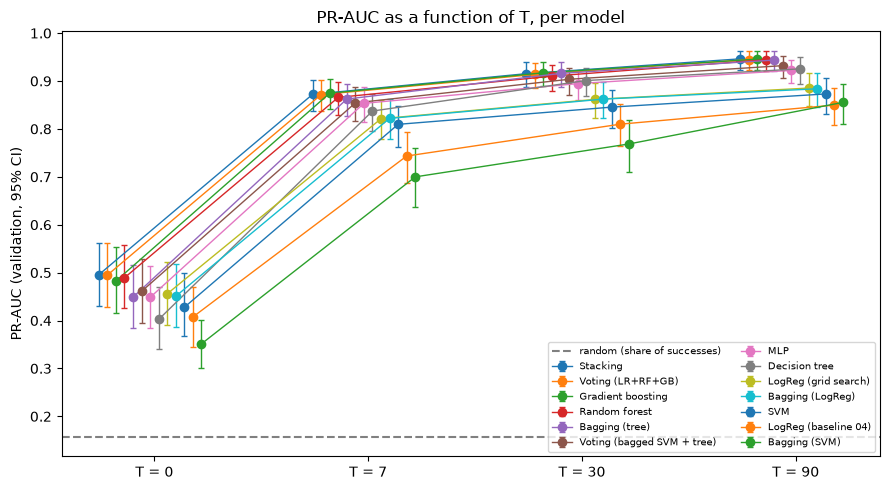

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
order = results.groupby("model")["PR-AUC"].mean().sort_values(ascending=False).index
for k, m in enumerate(order):
    r = results[results["model"] == m].sort_values("T")
    x = np.arange(len(T_LIST)) + (k - len(order) / 2) * 0.04
    ax.errorbar(x, r["PR-AUC"], yerr=[r["PR-AUC"] - r["CI_low"], r["CI_high"] - r["PR-AUC"]],
                marker="o", capsize=2, lw=1, label=m)
ax.axhline(y_val.mean(), color="gray", ls="--", label="random (share of successes)")
ax.set_xticks(range(len(T_LIST)), [f"T = {T}" for T in T_LIST])
ax.set(ylabel="PR-AUC (validation, 95% CI)", title="PR-AUC as a function of T, per model")
ax.legend(fontsize=7, ncol=2, loc="lower right"); plt.tight_layout()
plt.savefig(FIG_DIR / "prauc_vs_T_models.png", dpi=150); plt.show()

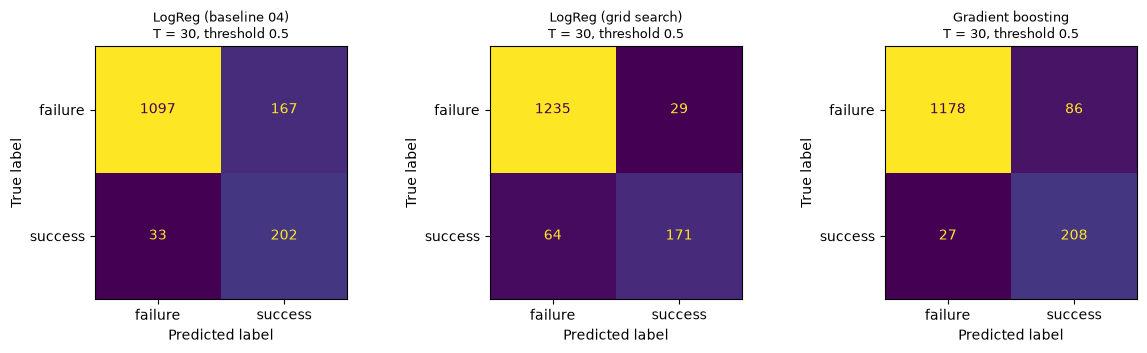

In [18]:
best_T30 = results[results["T"] == 30].sort_values("PR-AUC", ascending=False)["model"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, m in zip(axes, ["LogReg (baseline 04)", "LogReg (grid search)", best_T30]):
    p = PROBA[(m, 30)]
    ConfusionMatrixDisplay.from_predictions(y_val, (p >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["failure", "success"])
    ax.set_title(f"{m}\nT = 30, threshold 0.5", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_T30.png", dpi=150); plt.show()

In [19]:
INTERPRETABILITY = {
    "LogReg (baseline 04)": "high (coefficients)", "LogReg (grid search)": "high (coefficients)",
    "Decision tree": "high (rules, plot_tree)", "Bagging (LogReg)": "medium (average of 25-50 models)",
    "Random forest": "low (importances only)", "Gradient boosting": "low (importances only)",
    "MLP": "very low (black box)", "SVM": "very low (black box, RBF kernel)",
    "Bagging (SVM)": "very low", "Bagging (tree)": "low (average of trees)",
    "Voting (bagged SVM + tree)": "very low", "Voting (LR+RF+GB)": "low", "Stacking": "low"}
table = results[results["T"] == 30][["model", "PR-AUC", "CI_low", "CI_high", "ROC-AUC", "F1", "fit_s", "predict_s"]].copy()
table["interpretability"] = table["model"].map(INTERPRETABILITY)
table = table.sort_values("PR-AUC", ascending=False).round(3)
table

,model,PR-AUC,CI_low,CI_high,ROC-AUC,F1,fit_s,predict_s,interpretability
18,Gradient boosting,0.917,0.890,0.941,0.974,0.786,8.126,0.057,low (importances only)
35,Bagging (tree),0.916,0.888,0.939,0.976,0.824,1.215,0.261,low (average of trees)
48,Stacking,0.915,0.887,0.939,0.974,0.833,49.253,0.173,low
46,Voting (LR+RF+GB),0.914,0.885,0.937,0.973,0.833,14.963,0.152,low
14,Random forest,0.910,0.880,0.934,0.973,0.838,10.116,0.133,low (importances only)
36,Voting (bagged SVM + tree),0.904,0.871,0.928,0.973,0.805,6.585,4.629,very low
10,Decision tree,0.901,0.870,0.927,0.968,0.838,0.229,0.030,"high (rules, plot_tree)"
22,MLP,0.895,0.861,0.920,0.968,0.794,3.911,0.030,very low (black box)
47,Bagging (LogReg),0.862,0.823,0.897,0.957,0.780,64.400,0.382,medium (average of 25-50 models)
5,LogReg (grid search),0.862,0.823,0.896,0.956,0.786,1.276,0.031,high (coefficients)


In [20]:
results.round(4).to_csv(ROOT / "report" / "results_models.csv", index=False)
diff.round(4).to_csv(ROOT / "report" / "results_models_vs_baseline.csv", index=False)

# Validation probabilities of every model, for the error analysis (notebook 07)
val_ids = DATA[0]["df"].loc[DATA[0]["Xva"].index, "app_id"].to_numpy()
for T in T_LIST:
    assert (DATA[T]["df"].loc[DATA[T]["Xva"].index, "app_id"].to_numpy() == val_ids).all()
proba_table = pd.concat([pd.DataFrame({"model": m, "T": T, "app_id": val_ids, "proba": p})
                         for (m, T), p in PROBA.items()])
proba_table.to_parquet(PROC_DIR / "val_proba.parquet", index=False)
print("written: report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png, val_proba.parquet")

written: report/results_models.csv, report/results_models_vs_baseline.csv, report/figures/*.png, val_proba.parquet


## 8. Impact of the hours-played leak (AI_AUDIT, Flaw 2)

Module 3 removed `hours_mean` and `hours_median` from the early signals: the hours are read **at collection
time**, not at review time (13.6% of the first-month reviews have more hours than the time elapsed since
release). The impact on the model was missing. We recompute these two features at T = 30 from
`data/raw/recommendations.csv`, for the same games and with the same window `0 <= days < 30`, and compare the
baseline of notebook 04 with and without them.

In [21]:
raw = RAW_DIR / "recommendations.csv"
if raw.exists():
    rel = target.set_index("app_id")["release_date"]
    rev = pd.read_csv(raw, usecols=["app_id", "date", "hours"], engine="pyarrow")
    rev = rev[rev["app_id"].isin(rel.index)]
    rev["days"] = (pd.to_datetime(rev["date"]) - rev["app_id"].map(rel)).dt.days
    hours = (rev[(rev["days"] >= 0) & (rev["days"] < 30)]
             .groupby("app_id")["hours"].agg(hours_mean="mean", hours_median="median"))

    d = DATA[30]
    with_h = dict(d)  # same games and same target, we only add the two hours columns
    with_h["Xtr"] = d["Xtr"].assign(**hours.reindex(d["df"].loc[d["Xtr"].index, "app_id"]).set_index(d["Xtr"].index))
    with_h["Xva"] = d["Xva"].assign(**hours.reindex(d["df"].loc[d["Xva"].index, "app_id"]).set_index(d["Xva"].index))

    NUM_H = NUM_COLS + ["hours_mean", "hours_median"]
    pre_h = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_H),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS), remainder="passthrough")
    m_h = make_pipeline(pre_h, LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    m_h.fit(with_h["Xtr"], with_h["ytr"])
    p_h = m_h.predict_proba(with_h["Xva"])[:, 1]
    ap_without = average_precision_score(y_val, PROBA[("LogReg (baseline 04)", 30)])
    ap_with = average_precision_score(y_val, p_h)
    delta = boot_scores(p_h) - BOOT[("LogReg (baseline 04)", 30)]
    print(f"Validation PR-AUC at T=30: without the hours {ap_without:.3f} | with the hours (leak) {ap_with:.3f}")
    print(f"difference {ap_with - ap_without:+.3f}, 95% CI [{np.percentile(delta, 2.5):+.3f}, {np.percentile(delta, 97.5):+.3f}]")
else:
    print("data/raw/recommendations.csv missing: section skipped")

Validation PR-AUC at T=30: without the hours 0.810 | with the hours (leak) 0.809
difference -0.001, 95% CI [-0.005, +0.003]


## 9. Final evaluation on the test set (only once, Lucas GREZES)

The test set has not been used so far. When the group has chosen the final model **on the validation set**, set
`RUN_TEST = True` and run **only once**: the model is retrained on train + validation, then evaluated on the
test set with a 95% CI. The decision threshold (for the F1) is chosen on the validation set, not on the test set.

In [22]:
RUN_TEST = False
FINAL_MODEL, FINAL_T = best_T30, 30   # to be confirmed with the group

if RUN_TEST:
    df = DATA[FINAL_T]["df"]
    X_cols = DATA[FINAL_T]["Xtr"].columns
    trva, te = df[df["split"].isin(["train", "val"])], df[df["split"] == "test"]
    # threshold that maximises the F1 on the validation set
    p_val = PROBA[(FINAL_MODEL, FINAL_T)]
    thr = max(np.linspace(0.05, 0.95, 91), key=lambda t: f1_score(y_val, (p_val >= t).astype(int)))
    model = clone(MODELS[(FINAL_MODEL, FINAL_T)]).fit(trva[X_cols], trva["success"])
    p = model.predict_proba(te[X_cols])[:, 1]
    y_te = te["success"].to_numpy()
    idx = [i for i in (np.random.default_rng(SEED).integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)) if y_te[i].any()]
    s = [average_precision_score(y_te[i], p[i]) for i in idx]
    print(f"TEST {FINAL_MODEL}, T={FINAL_T}: PR-AUC = {average_precision_score(y_te, p):.3f} "
          f"[{np.percentile(s, 2.5):.3f}, {np.percentile(s, 97.5):.3f}], ROC-AUC = {roc_auc_score(y_te, p):.3f}, "
          f"F1 (threshold {thr:.2f} chosen on validation) = {f1_score(y_te, (p >= thr).astype(int)):.3f}")
else:
    print("Test set not used (RUN_TEST = False).")

Test set not used (RUN_TEST = False).
